### Baseline DeepONet: two splitting protocols, **Pipeline.** CO2 GCS dataset -> preprocessing -> physics-based feature engineering ->case-level splitting -> feature scaling -> Baseline DeepONet -> metrics -> decision support.**Architecture.** Four independent sigmoid heads. Closure (STTI+RTI+STI+MTI = 1) is encouraged by a penalty only, so predictions can leave the simplex.All modelling code lives in the `co2gcs` package so that the four notebooks shareone implementation. Put `co2gcs/` and `All_dataset.csv` next to this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import co2gcs as CC
CC.plots.use_style()
SEED = 42
TARGETS = CC.TARGETS

## 1. Data and physics-based feature engineering

In [2]:
# ---- Load + physics-based feature engineering -------------------------------

# fix_injection=True restores each case's injection rate over the full trajectory.
# In the raw file, the column is zeroed for every t > 30 yr, which leaks the
# post-injection regime label and deletes the strongest control on long-term
# trapping across 85% of the horizon.

df = CC.load('All_dataset.csv', fix_injection=True)

Xb, Xt, y, names_b, names_t = CC.build_features(df, mode='fixed')

groups = df['case'].values
tvals = df['Time (years)'].values

print(
    f'{len(df)} rows, {df.case.nunique()} simulation cases, '
    f'branch dim {Xb.shape[1]}, trunk dim {Xt.shape[1]}'
)

df.head()

47425 rows, 761 simulation cases, branch dim 16, trunk dim 5


,Index,Dykstra Parson Coefficient,Average Porosity,Injection rate (m3/day),Biots Coefficient,Young's Modulus (MPa),Poisson's Ratio,Perforation Thickness (m),Reservoir Thickness (m),Acquifer Salinity (PPM),Reservoir Temperature (oC),Time (years),STTI,RTI,STI,MTI,case,q_inj
0,1,0.54,0.2,2.4,0.86,10.0,0.23,48.6,108.0,15000.0,86.0,0.41,0.1161,0.0014,0.8845,0.0019,0,2.4
1,2,0.54,0.2,2.4,0.86,10.0,0.23,48.6,108.0,15000.0,86.0,0.50,0.2356,0.0011,0.7651,0.0019,0,2.4
2,3,0.54,0.2,2.4,0.86,10.0,0.23,48.6,108.0,15000.0,86.0,0.58,0.3145,0.0010,0.6863,0.0019,0,2.4
3,4,0.54,0.2,2.4,0.86,10.0,0.23,48.6,108.0,15000.0,86.0,0.67,0.3842,0.0009,0.6167,0.0018,0,2.4
4,5,0.54,0.2,2.4,0.86,10.0,0.23,48.6,108.0,15000.0,86.0,0.75,0.4221,0.0010,0.5787,0.0019,0,2.4


## 2. Splitting protocols

In [3]:
# ---- The two splitting protocols --------------------------------------------

PROTOCOLS = ['random', 'group']


def get_split(protocol, fold=0):
    tr, va, te = CC.make_split(
        protocol,
        len(y),
        groups,
        seed=SEED,
        n_folds=5,
        fold=fold
    )

    # Scalers fit on TRAIN ONLY
    sb = StandardScaler().fit(Xb[tr])
    st = StandardScaler().fit(Xt[tr])

    pack = lambda m: (
        sb.transform(Xb[m]).astype('float32'),
        st.transform(Xt[m]).astype('float32'),
        y[m]
    )

    d = {}

    for nm, m in [('tr', tr), ('va', va), ('te', te)]:
        d[f'Xb_{nm}'], d[f'Xt_{nm}'], d[f'y_{nm}'] = pack(m)

    d.update(
        t_te=tvals[te],
        g_te=groups[te],
        mask_te=te,
        dims=(Xb.shape[1], Xt.shape[1]),
        scalers=(sb, st)
    )

    return d


for p in PROTOCOLS:
    d = get_split(p)

    print(
        f"{p:7s} "
        f"train {len(d['y_tr']):6d}  "
        f"val {len(d['y_va']):5d}  "
        f"test {len(d['y_te']):5d}  "
        f"test cases {len(np.unique(d['g_te'])):4d}"
    )

random  train  33199  val  7113  test  7113  test cases  761
group   train  30762  val  7057  test  9606  test cases  153


### Pros and cons of each protocol

In [4]:
for p in PROTOCOLS:
    n = CC.PROTOCOL_NOTES[p]

    print('=' * 78)
    print(n['name'])
    print('=' * 78)

    print(' PROS')
    [print('   +', x) for x in n['pros']]

    print(' CONS')
    [print('   -', x) for x in n['cons']]

    print()

Protocol 1 - random row split
 PROS
   + Maximises training rows for a fixed ensemble size.
   + Appropriate if the deployment task is gap-filling or temporal interpolation within simulations that are already available.
   + Low variance between repeats, so results look stable.
 CONS
   - Neighbouring timesteps of the same trajectory land in both train and test, so the test set is not independent of training.
   - Reported R2 measures interpolation along a seen curve, not generalisation to a new reservoir.
   - Smooth, slowly varying indices (MTI in particular) are inflated most, because the neighbouring years almost determine the answer.
   - Hides loss-weighting and feature defects that only appear when the model must extrapolate to an unseen case.

Protocol 2 - GroupKFold by simulation case
 PROS
   + Test cases are fully unseen, matching the site-screening use case where a new reservoir realisation must be scored.
   + Exposes genuine parameter-to-response learning rather than curv

## 3. Train and compare the protocols

In [5]:
# ---- Train one model per protocol -------------------------------------------

db, dt = Xb.shape[1], Xt.shape[1]

TRAIN_KW = dict(
    epochs=500,
    patience=20,
    bs=32,
    lr=1.5e-3,
    wd=8.5e-5,
    var_weight=True,
    closure_pen=1.0
)

results, preds, splits, models = [], {}, {}, {}

for p in PROTOCOLS:
    d = get_split(p)
    splits[p] = d

    CC.seed_all(SEED)

    drop, head, bayes = 0.0, 'point', False

    model = CC.BaselineDeepONet(
        db,
        dt,
        p_drop=drop,
        head=head,
        bayes_last=bayes
    )

    model, hist = CC.train_model(
        model,
        d['Xb_tr'],
        d['Xt_tr'],
        d['y_tr'],
        d['Xb_va'],
        d['Xt_va'],
        d['y_va'],
        head= head,
        **TRAIN_KW
    )
    
    models[p] = model
    
    P = CC.predict_mean(
        model,
        d['Xb_te'],
        d['Xt_te']
    )

    preds[p] = P

    m = CC.accuracy(d['y_te'], P)
    m['protocol'] = p
    results.append(m)

    print(
        f"{p:7s} R2_mean={m['R2_mean']:.4f}  "
        + '  '.join(
            f'{t}={m[f"R2_{t}"]:.3f}'
            for t in TARGETS
        )
        + f"  closureMAE={m['closure_MAE']:.4f}"
    )

res = pd.DataFrame(results)[
    ['protocol']
    + [f'R2_{t}' for t in TARGETS]
    + ['R2_mean']
    + [f'RMSE_{t}' for t in TARGETS]
    + ['MAE_mean', 'closure_MAE']
]

res.round(4)

random  R2_mean=0.9968  STTI=0.997  RTI=0.997  STI=0.997  MTI=0.997  closureMAE=0.0005
group   R2_mean=0.9731  STTI=0.973  RTI=0.977  STI=0.981  MTI=0.961  closureMAE=0.0009


,protocol,R2_STTI,R2_RTI,R2_STI,R2_MTI,R2_mean,RMSE_STTI,RMSE_RTI,RMSE_STI,RMSE_MTI,MAE_mean,closure_MAE
0,random,0.9966,0.9968,0.9968,0.9970,0.9968,0.0117,0.0077,0.0081,0.0006,0.0048,0.0005
1,group,0.9731,0.9773,0.9806,0.9611,0.9731,0.0326,0.0208,0.0191,0.0017,0.0124,0.0009


### RandomKFold spread

In [6]:
# ---- 5-fold RandomKFold: fold-to-fold spread -------------------------------

fold_rows = []

for f in range(5):
    d = get_split('random', fold=f)

    CC.seed_all(SEED + f)

    drop, head, bayes = 0.0, 'point', False

    model = CC.BaselineDeepONet(
        db,
        dt,
        p_drop=drop,
        head=head,
        bayes_last=bayes
    )

    model, _ = CC.train_model(
        model,
        d['Xb_tr'],
        d['Xt_tr'],
        d['y_tr'],
        d['Xb_va'],
        d['Xt_va'],
        d['y_va'],
        head='point',
        **TRAIN_KW
    )

    P = CC.predict_mean(
        model,
        d['Xb_te'],
        d['Xt_te']
    )

    # Calculate all metrics
    m = CC.accuracy(d['y_te'], P)
    m['fold'] = f
    fold_rows.append(m)

    # Print fold results
    print(f"\n{'=' * 65}")
    print(f"Fold {f}")
    print(f"{'=' * 65}")

    print(
        f"{'Index':<10}"
        f"{'R²':>12}"
        f"{'RMSE':>12}"
        f"{'MAE':>12}"
    )

    print("-" * 65)

    for t in TARGETS:
        print(
            f"{t:<10}"
            f"{m[f'R2_{t}']:>12.4f}"
            f"{m[f'RMSE_{t}']:>12.4f}"
            f"{m[f'MAE_{t}']:>12.4f}"
        )

    print("-" * 65)

    print(
        f"{'Mean':<10}"
        f"{m['R2_mean']:>12.4f}"
        f"{m['RMSE_mean']:>12.4f}"
        f"{m['MAE_mean']:>12.4f}"
    )

folds = pd.DataFrame(fold_rows)

print("\n" + "=" * 65)
print(
    "RandomKFold R2_mean = %.4f +/- %.4f"
    % (folds.R2_mean.mean(), folds.R2_mean.std())
)
print("=" * 65)


Fold 0
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.9966      0.0117      0.0078
RTI             0.9968      0.0077      0.0052
STI             0.9968      0.0081      0.0057
MTI             0.9970      0.0006      0.0004
-----------------------------------------------------------------
Mean            0.9968      0.0070      0.0048

Fold 1
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.9978      0.0095      0.0062
RTI             0.9979      0.0063      0.0039
STI             0.9981      0.0063      0.0042
MTI             0.9977      0.0005      0.0003
-----------------------------------------------------------------
Mean            0.9979      0.0056      0.0037

Fold 2
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.9959      0.0129 

In [7]:
# ---- detailed fold metrics -----------------------------------------------

fold_metrics = []

for m in fold_rows:
    for t in TARGETS:
        fold_metrics.append({
            'fold': m['fold'],
            'index': t,
            'R2': m[f'R2_{t}'],
            'RMSE': m[f'RMSE_{t}'],
            'MAE': m[f'MAE_{t}']
        })

fold_metrics = pd.DataFrame(fold_metrics)

fold_metrics.round(4)

,fold,index,R2,RMSE,MAE
0,0,STTI,0.9966,0.0117,0.0078
1,0,RTI,0.9968,0.0077,0.0052
2,0,STI,0.9968,0.0081,0.0057
3,0,MTI,0.9970,0.0006,0.0004
4,1,STTI,0.9978,0.0095,0.0062
5,1,RTI,0.9979,0.0063,0.0039
6,1,STI,0.9981,0.0063,0.0042
7,1,MTI,0.9977,0.0005,0.0003
8,2,STTI,0.9959,0.0129,0.0091
9,2,RTI,0.9960,0.0087,0.0062


In [8]:
fold_summary = (
    fold_metrics
    .groupby('index')[['R2', 'RMSE', 'MAE']]
    .agg(['mean', 'std'])
)

fold_summary.round(4)

R2            RMSE             MAE        
         mean     std    mean     std    mean     std
index                                                
MTI    0.9973  0.0014  0.0005  0.0001  0.0003  0.0001
RTI    0.9974  0.0010  0.0068  0.0014  0.0044  0.0014
STI    0.9976  0.0012  0.0068  0.0018  0.0046  0.0013
STTI   0.9973  0.0011  0.0102  0.0022  0.0067  0.0019

### GroupKFold spread

In [9]:
# ---- 5-fold GroupKFold: fold-to-fold spread is the deployment variance -------

fold_rows = []

for f in range(5):
    d = get_split('group', fold=f)

    CC.seed_all(SEED + f)

    drop, head, bayes = 0.0, 'point', False

    model = CC.BaselineDeepONet(
        db,
        dt,
        p_drop=drop,
        head=head,
        bayes_last=bayes
    )

    model, _ = CC.train_model(
        model,
        d['Xb_tr'],
        d['Xt_tr'],
        d['y_tr'],
        d['Xb_va'],
        d['Xt_va'],
        d['y_va'],
        head='point',
        **TRAIN_KW
    )

    P = CC.predict_mean(
        model,
        d['Xb_te'],
        d['Xt_te']
    )

    # Calculate all metrics
    m = CC.accuracy(d['y_te'], P)
    m['fold'] = f
    fold_rows.append(m)

    # Print fold results
    print(f"\n{'=' * 65}")
    print(f"Fold {f}")
    print(f"{'=' * 65}")

    print(
        f"{'Index':<10}"
        f"{'R²':>12}"
        f"{'RMSE':>12}"
        f"{'MAE':>12}"
    )

    print("-" * 65)

    for t in TARGETS:
        print(
            f"{t:<10}"
            f"{m[f'R2_{t}']:>12.4f}"
            f"{m[f'RMSE_{t}']:>12.4f}"
            f"{m[f'MAE_{t}']:>12.4f}"
        )

    print("-" * 65)

    print(
        f"{'Mean':<10}"
        f"{m['R2_mean']:>12.4f}"
        f"{m['RMSE_mean']:>12.4f}"
        f"{m['MAE_mean']:>12.4f}"
    )

folds = pd.DataFrame(fold_rows)

print("\n" + "=" * 65)
print(
    "RandomKFold R2_mean = %.4f +/- %.4f"
    % (folds.R2_mean.mean(), folds.R2_mean.std())
)
print("=" * 65)


Fold 0
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.9731      0.0326      0.0216
RTI             0.9773      0.0208      0.0139
STI             0.9806      0.0191      0.0132
MTI             0.9611      0.0017      0.0009
-----------------------------------------------------------------
Mean            0.9731      0.0186      0.0124

Fold 1
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.9691      0.0355      0.0237
RTI             0.9734      0.0229      0.0158
STI             0.9780      0.0204      0.0139
MTI             0.9693      0.0019      0.0011
-----------------------------------------------------------------
Mean            0.9725      0.0202      0.0136

Fold 2
Index               R²        RMSE         MAE
-----------------------------------------------------------------
STTI            0.9730      0.0330 

In [10]:
# ---- detailed fold metrics -----------------------------------------------

fold_metrics = []

for m in fold_rows:
    for t in TARGETS:
        fold_metrics.append({
            'fold': m['fold'],
            'index': t,
            'R2': m[f'R2_{t}'],
            'RMSE': m[f'RMSE_{t}'],
            'MAE': m[f'MAE_{t}']
        })

fold_metrics = pd.DataFrame(fold_metrics)

fold_metrics.round(4)

,fold,index,R2,RMSE,MAE
0,0,STTI,0.9731,0.0326,0.0216
1,0,RTI,0.9773,0.0208,0.0139
2,0,STI,0.9806,0.0191,0.0132
3,0,MTI,0.9611,0.0017,0.0009
4,1,STTI,0.9691,0.0355,0.0237
5,1,RTI,0.9734,0.0229,0.0158
6,1,STI,0.9780,0.0204,0.0139
7,1,MTI,0.9693,0.0019,0.0011
8,2,STTI,0.9730,0.0330,0.0222
9,2,RTI,0.9762,0.0215,0.0144


In [11]:
fold_summary = (
    fold_metrics
    .groupby('index')[['R2', 'RMSE', 'MAE']]
    .agg(['mean', 'std'])
)

fold_summary.round(4)

R2            RMSE             MAE        
         mean     std    mean     std    mean     std
index                                                
MTI    0.9584  0.0091  0.0021  0.0003  0.0010  0.0001
RTI    0.9734  0.0040  0.0228  0.0018  0.0151  0.0009
STI    0.9802  0.0024  0.0194  0.0013  0.0135  0.0008
STTI   0.9689  0.0043  0.0354  0.0027  0.0236  0.0017

## 4. Performance figures

In [12]:
import os

os.makedirs('figures_protocols', exist_ok=True)

CC.plots.fig_protocol_bars(
    res,
    'figures_protocols/baseline_protocol_bars.png',
    title='Baseline DeepONet: accuracy under both protocols'
)

CC.plots.fig_parity(
    {
        'Protocol 1: random rows': splits['random']['y_te'],
        'Protocol 2: unseen cases': splits['group']['y_te']
    },
    {
        'Protocol 1: random rows': preds['random'],
        'Protocol 2: unseen cases': preds['group']
    },
    'figures_protocols/baseline_parity.png',
    title='Baseline DeepONet: parity by protocol'
)

CC.plots.fig_trajectories(
    splits,
    preds,
    'figures_protocols/baseline_trajectories.png',
    n=5,
    title='Baseline DeepONet: five randomly drawn simulations'
)

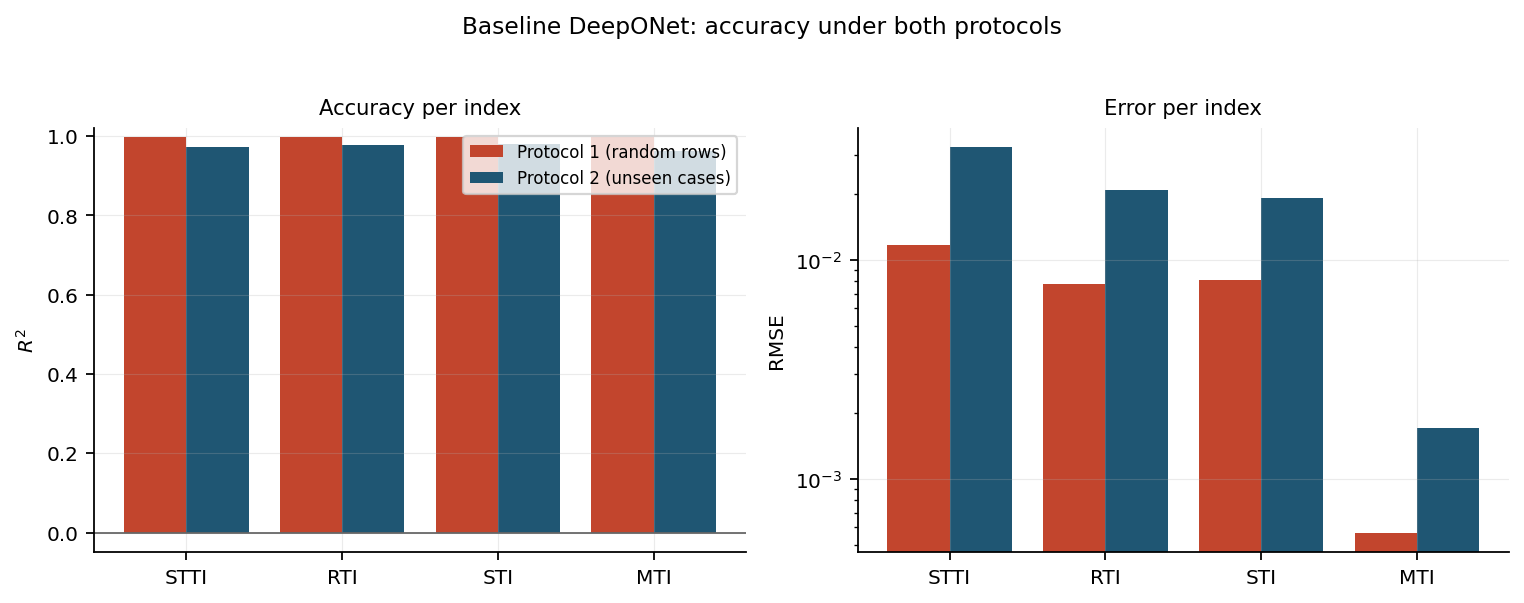

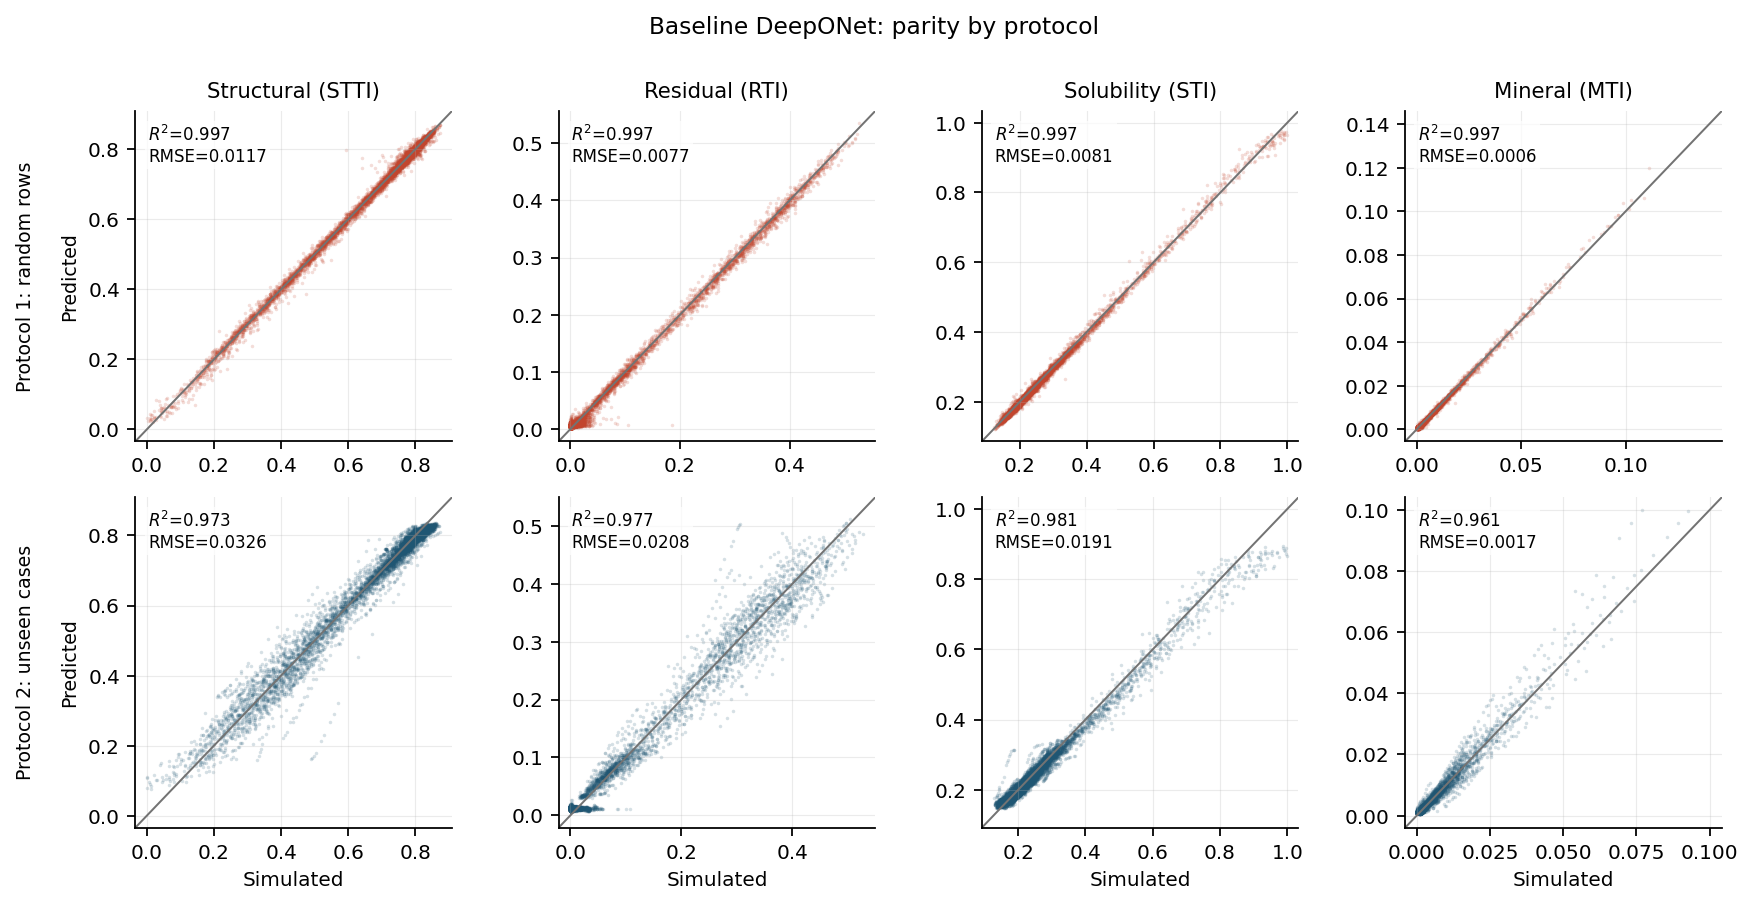

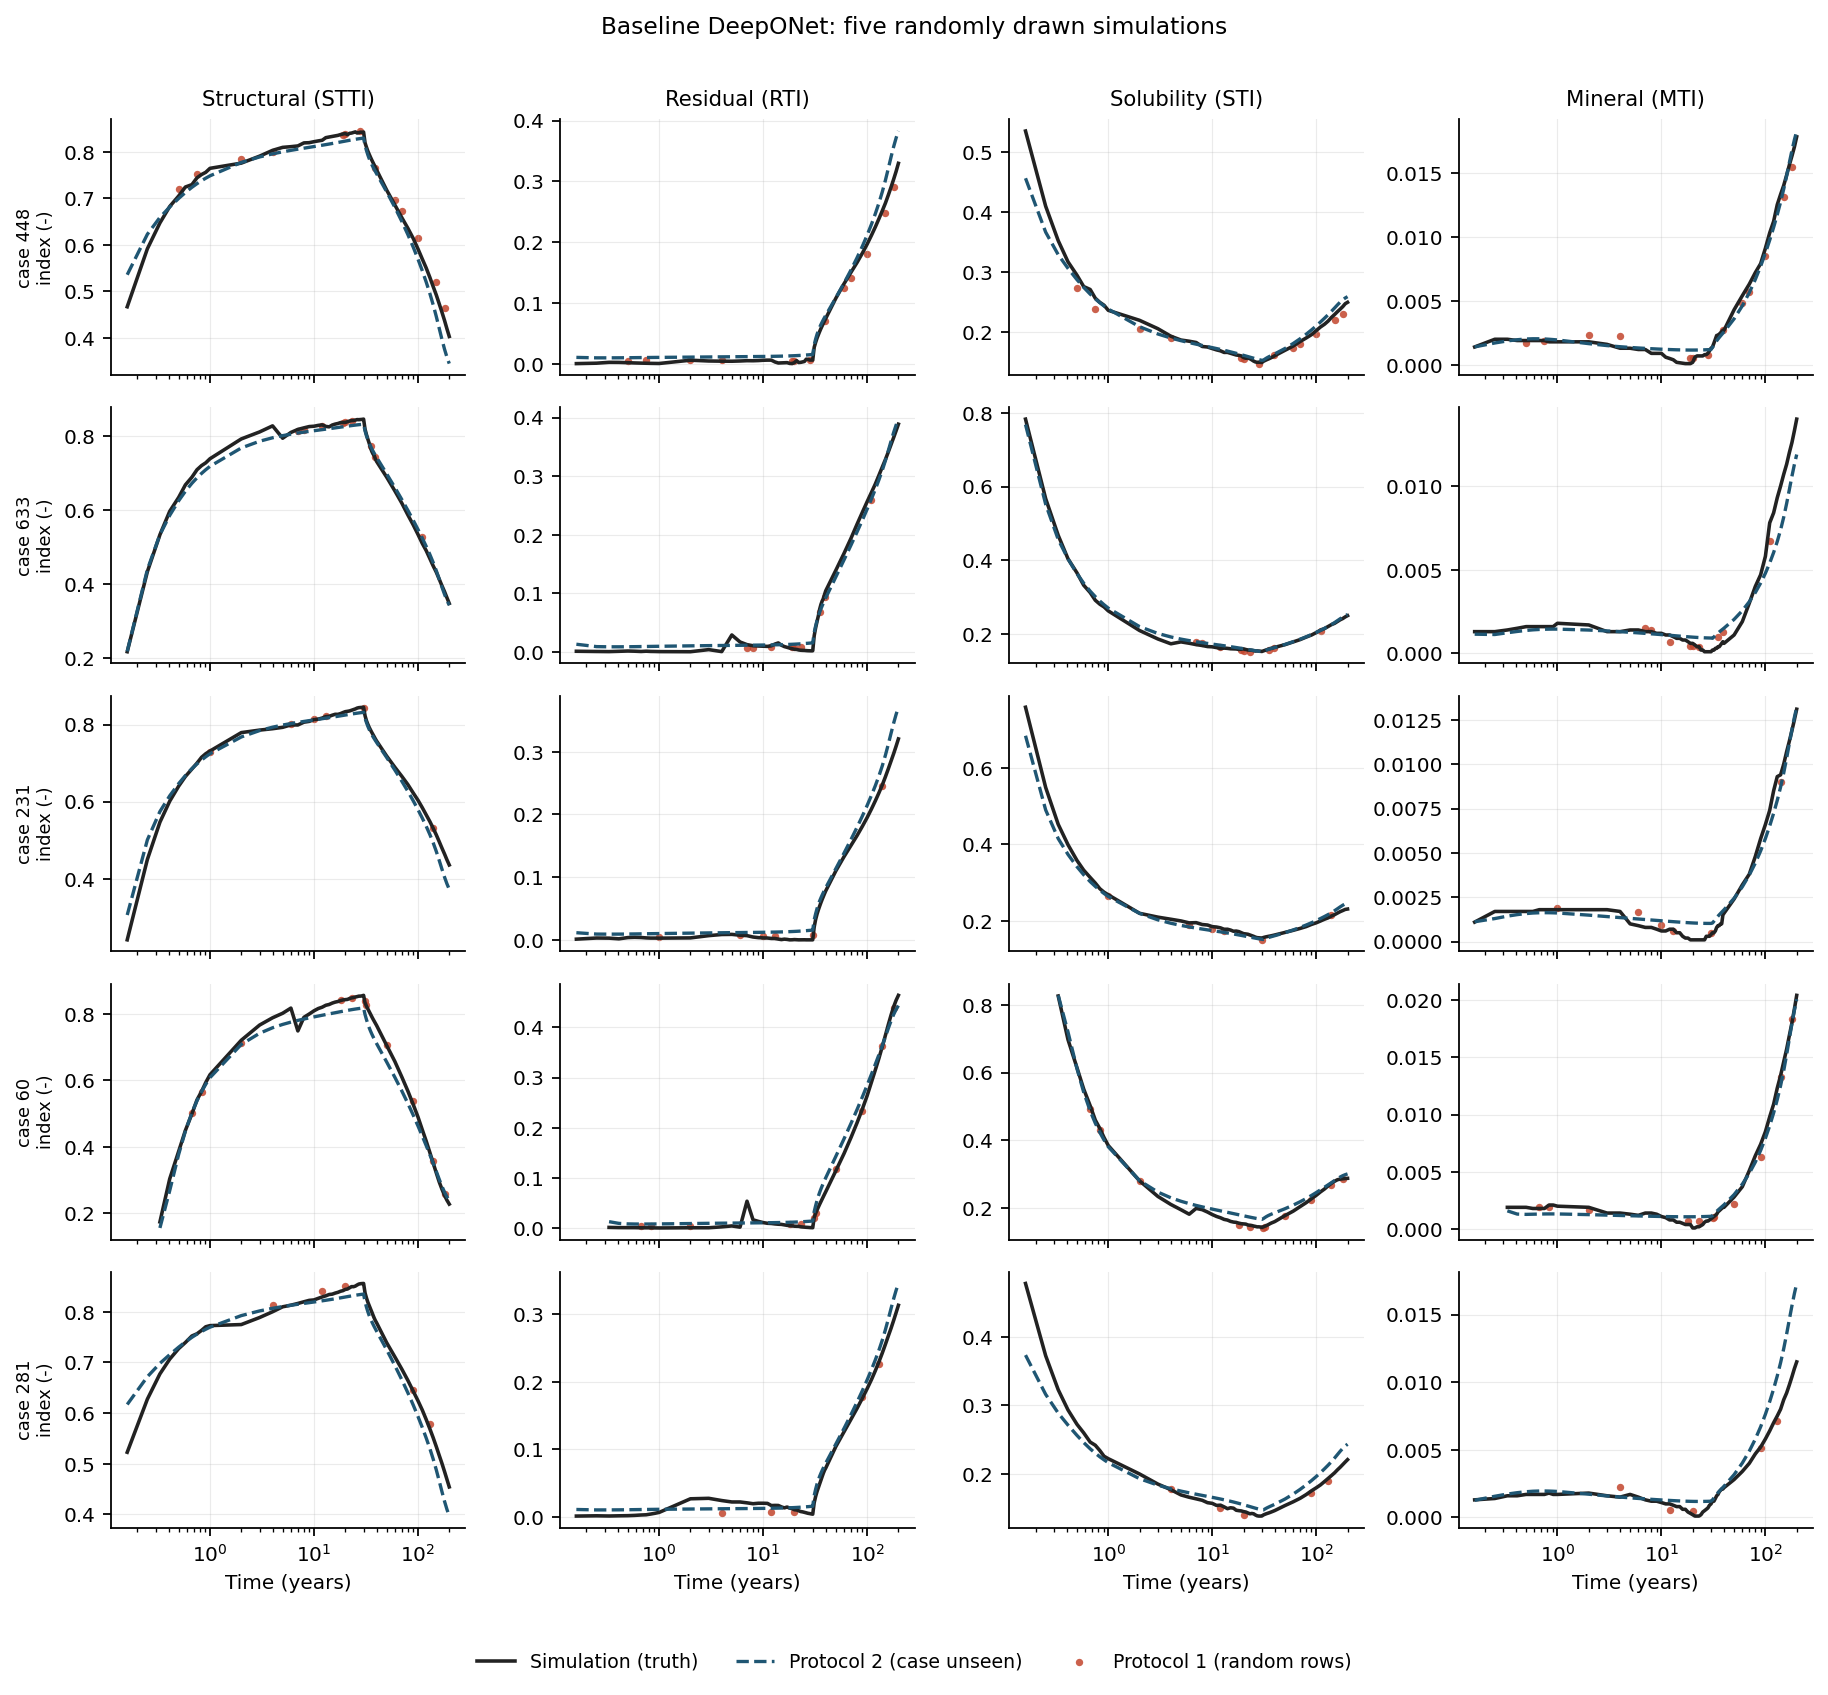

In [13]:
from IPython.display import Image, display

for f in [
    'baseline_protocol_bars',
    'baseline_parity',
    'baseline_trajectories'
]:
    display(Image(filename=f'figures_protocols/{f}.png'))

### Performance plot

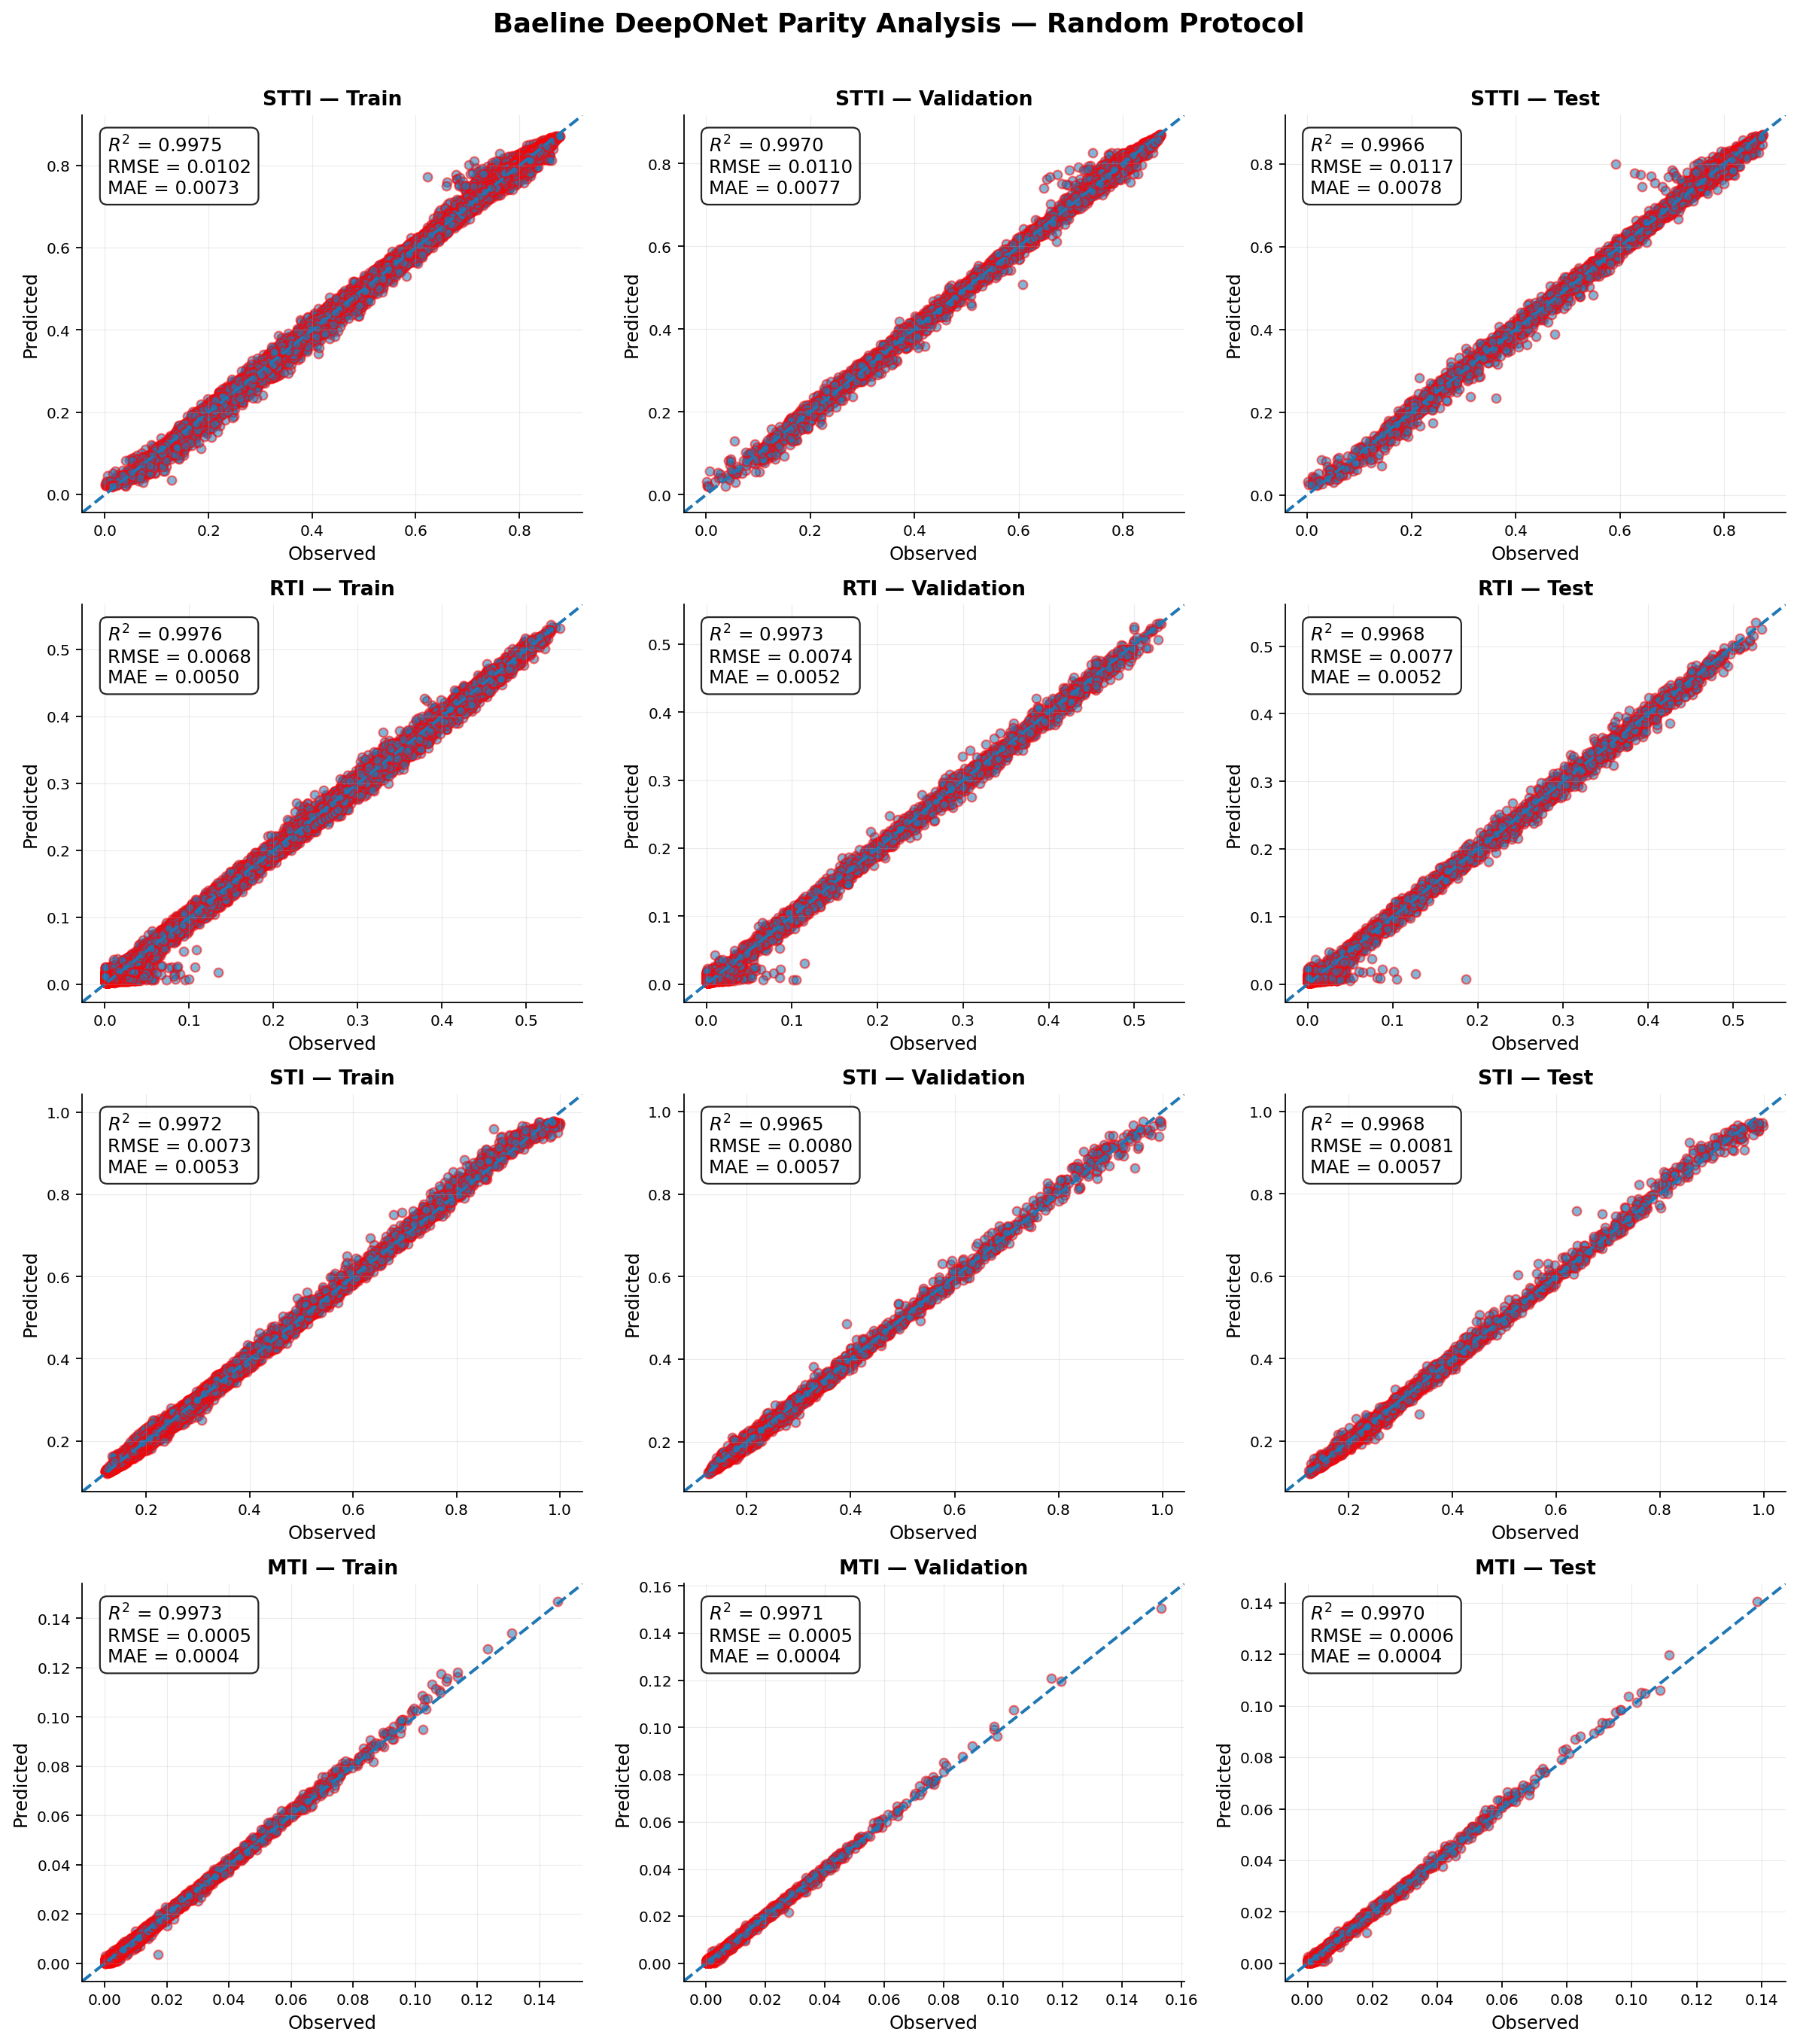

Saved: figures_protocols/baseline_parity_train_val_test_random.png


In [14]:
# ---- Baseline DeepONet: Train / Validation / Test parity plot ---------------
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('figures_protocols', exist_ok=True)

# ---------------------------------------------------------------------------
# Select the protocol you want to visualize
# ---------------------------------------------------------------------------
protocol = 'random'
model = models[protocol]
d = splits[protocol]

# Predictions for train / validation / test
P_tr = CC.predict_mean(model, d['Xb_tr'], d['Xt_tr'])
P_va = CC.predict_mean(model, d['Xb_va'], d['Xt_va'])
P_te = CC.predict_mean(model, d['Xb_te'], d['Xt_te'])

Y_tr = d['y_tr']
Y_va = d['y_va']
Y_te = d['y_te']

# ---------------------------------------------------------------------------
# Metric function
# ---------------------------------------------------------------------------
def parity_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    r2 = 1.0 - np.sum((y_true - y_pred) ** 2) / (
        np.sum((y_true - np.mean(y_true)) ** 2) + 1e-12
    )

    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae = np.mean(np.abs(y_true - y_pred))

    return r2, rmse, mae


# ---------------------------------------------------------------------------
# Create 4 × 3 parity figure
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(
    len(TARGETS),
    3,
    figsize=(15, 17)
)

sets = [
    ('Train', Y_tr, P_tr),
    ('Validation', Y_va, P_va),
    ('Test', Y_te, P_te)
]

for i, target in enumerate(TARGETS):

    for j, (set_name, y_true, y_pred) in enumerate(sets):

        ax = axes[i, j]

        yt = y_true[:, i]
        yp = y_pred[:, i]

        r2, rmse, mae = parity_metrics(yt, yp)

        # Determine common axis limits
        lo = min(yt.min(), yp.min())
        hi = max(yt.max(), yp.max())

        pad = 0.05 * (hi - lo + 1e-12)
        lo -= pad
        hi += pad

        # Scatter
        ax.scatter(
            yt,
            yp,
            alpha=0.55,
            s=28,
            edgecolors='red'
        )

        # 1:1 parity line
        ax.plot(
            [lo, hi],
            [lo, hi],
            linestyle='--',
            linewidth=1.8
        )

        # Metrics box
        ax.text(
            0.05,
            0.95,
            f'$R^2$ = {r2:.4f}\n'
            f'RMSE = {rmse:.4f}\n'
            f'MAE = {mae:.4f}',
            transform=ax.transAxes,
            verticalalignment='top',
            fontsize=11,
            bbox=dict(
                boxstyle='round,pad=0.4',
                facecolor='white',
                alpha=0.85
            )
        )

        # Labels
        ax.set_xlabel('Observed', fontsize=11)
        ax.set_ylabel('Predicted', fontsize=11)

        ax.set_title(
            f'{target} — {set_name}',
            fontsize=12,
            fontweight='bold'
        )

        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)

        ax.grid(
            True,
            alpha=0.25
        )

# Overall title
fig.suptitle(
    f'Baeline DeepONet Parity Analysis — {protocol.capitalize()} Protocol',
    fontsize=16,
    fontweight='bold',
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.985])

# Save
outfile = (
    f'figures_protocols/'
    f'baseline_parity_train_val_test_{protocol}.png'
)

plt.savefig(
    outfile,
    dpi=600,
    bbox_inches='tight'
)

plt.show()

print(f'Saved: {outfile}')

### Uncertainty quantificationThree engines are implemented and selectable through `METHOD`:| method | cost | epistemic source | notes ||---|---|---|---|| `mc_dropout` | 1 training run + S passes | dropout masks | cheapest; the dropout rate is an unprincipled knob and it tends to be over-dispersed in a way that flatters PICP while worsening ECE || `deep_ensemble` | M training runs | independent optima | strongest and best calibrated after recalibration; recommended default || `bayesian` | 1 training run | variational posterior on the final projection | principled and cheap. Natural for a DeepONet because the output is *linear in the learned basis*, so the last layer carries most of the predictive uncertainty. Full VI over every weight costs far more and does not generally beat ensembles |`deterministic` is included as an accuracy reference only; PICP and ECE aredegenerate for it because it has no predictive spread.**Aleatoric vs. epistemic.** The head supplies aleatoric noise, the enginesupplies epistemic spread, and the two combine by the law of total variance(`C.decompose`).Aleatoric noise is a **heteroscedastic Gaussian** head: the network emits `(mu, log sigma^2)` per index. Samples are not constrained to the simplex, so closure violation is a metric worth reporting.**Calibration is not optional.** Ensembles and the Bayesian layer come outunder-dispersed on unseen cases; a single post-hoc scale factor per index,fitted on the validation partition, brings observed coverage back to nominalwithout touching the predictive mean.

In [15]:
RENORM = False   # keep recalibrated samples on the simplex

In [16]:
# ---- select the UQ engine ---------------------------------------------------

METHOD = 'deep_ensemble'      # 'mc_dropout' | 'deep_ensemble' | 'bayesian' | 'deterministic'

N_SAMPLES = 200               # stochastic forward passes
N_MEMBERS = 5                 # ensemble members
LEVEL = 0.90                  # nominal prediction interval
HEAD = 'logitnormal'
P_DROP = 0.10


def build(method):
    """
    Build the Closure DeepONet factory and return the
    corresponding prediction head.
    """

    drop = P_DROP if method == 'mc_dropout' else 0.0
    bayes = method == 'bayesian'
    head = HEAD if method != 'deterministic' else 'point'

    db, dt = Xb.shape[1], Xt.shape[1]

    fn = lambda seed: CC.BaselineDeepONet(
        db,
        dt,
        p_drop=drop,
        head=head,
        bayes_last=bayes
    )

    return fn, head


def run_one(method, protocol):
    """
    Run one UQ method on one evaluation protocol.
    """

    d = get_split(protocol)

    fn, head = build(method)

    # Copy training configuration so the original TRAIN_KW
    # is not modified.
    tk = dict(TRAIN_KW)

    # Make training head consistent with model head.
    tk['head'] = head

    # Bayesian regularization
    if method == 'bayesian':
        tk['kl_weight'] = 0.05

    r = CC.run_uq(
        method,
        fn,
        d,
        head=head,
        n_samples=N_SAMPLES,
        n_members=N_MEMBERS,
        seed=SEED,
        train_kw=tk
    )

    return d, r, head

### Run every engine under both protocols

In [17]:
# ---- run every engine under both protocols -------------------------------

METHODS = [
    'deterministic',
    'mc_dropout',
    'deep_ensemble',
    'bayesian'
]

rows = []
store = {}

for protocol in PROTOCOLS:

    for method in METHODS:

        print(f'\nRunning {method} under {protocol} protocol...')

        # ---------------------------------------------------------------
        # Train / generate predictive samples
        # ---------------------------------------------------------------
        d, r, head = run_one(method, protocol)

        S = r['samples']

        # ---------------------------------------------------------------
        # Validation-only variance recalibration
        # ---------------------------------------------------------------
        if method != 'deterministic':

            from co2gcs.uq import _forward_all, _enable_dropout

            rng = np.random.default_rng(SEED)

            Sv = []

            for model_i in r['models']:

                # MC Dropout requires dropout to be active
                if method == 'mc_dropout':
                    _enable_dropout(model_i)

                for _ in range(10):

                    Sv.append(
                        _forward_all(
                            model_i,
                            d['Xb_va'],
                            d['Xt_va'],
                            head,
                            rng,
                            bayes_sample=(method == 'bayesian')
                        )
                    )

                model_i.eval()

            Sv = np.stack(Sv)

            # Fit variance scaling ONLY on validation data
            scale = CC.fit_variance_scaling(
                d['y_va'],
                Sv
            )

            # Apply calibration to test predictive samples
            S_cal = CC.apply_variance_scaling(
                S,
                scale,
                renormalise=RENORM
            )

        else:

            scale = np.ones(4)
            S_cal = S

        # ---------------------------------------------------------------
        # Uncalibrated test performance
        # ---------------------------------------------------------------
        met, cc = CC.summarise(
            d['y_te'],
            S,
            level=LEVEL
        )

        # ---------------------------------------------------------------
        # Calibrated test performance
        # ---------------------------------------------------------------
        metc, ccc = CC.summarise(
            d['y_te'],
            S_cal,
            level=LEVEL
        )

        # ---------------------------------------------------------------
        # Store summary results
        # ---------------------------------------------------------------
        rows.append(
            dict(
                protocol=protocol,
                method=method,
                **met,
                **{
                    f'cal_{k}': v
                    for k, v in metc.items()
                }
            )
        )

        # ---------------------------------------------------------------
        # Store samples and calibration information
        # ---------------------------------------------------------------
        store[(protocol, method)] = dict(
            S=S,
            S_cal=S_cal,
            cc=cc,
            cc_cal=ccc,
            d=d,
            scale=scale,
            head=head
        )

        # ---------------------------------------------------------------
        # Print summary
        # ---------------------------------------------------------------
        print(
            f'{protocol:7s} {method:14s} '
            f'R2={met["R2_mean"]:.4f} '
            f'PICP={met["PICP_mean"]:.3f}'
            f'->{metc["PICP_mean"]:.3f} '
            f'NMPIW={metc["NMPIW_mean"]:.3f} '
            f'CRPS={met["CRPS_mean"]:.4f} '
            f'ECE={met["ECE_mean"]:.3f}'
            f'->{metc["ECE_mean"]:.3f} '
            f'closure={met["closure_MAE"]:.4f}'
        )

# ---------------------------------------------------------------------------
# Final UQ summary table
# ---------------------------------------------------------------------------

uq = pd.DataFrame(rows)

uq_summary = uq[
    [
        'protocol',
        'method',
        'R2_mean',
        'RMSE_mean',
        'PICP_mean',
        'cal_PICP_mean',
        'cal_NMPIW_mean',
        'CRPS_mean',
        'ECE_mean',
        'cal_ECE_mean',
        'closure_MAE'
    ]
].round(4)

uq_summary


Running deterministic under random protocol...
random  deterministic  R2=0.9968 PICP=0.000->0.000 NMPIW=0.000 CRPS=0.0047 ECE=0.500->0.500 closure=0.0005

Running mc_dropout under random protocol...


ValueError: too many values to unpack (expected 2)

### Uncertainty figures

In [ ]:
# ---- UQ figures -------------------------------------------------------------
import os
import numpy as np

os.makedirs('figures_uq', exist_ok=True)

# Best-performing UQ method
best = 'deep_ensemble'

# ---------------------------------------------------------------------------
# 1. Reliability / calibration BEFORE variance recalibration
# ---------------------------------------------------------------------------
CC.plots.fig_calibration(
    {
        m: store[('group', m)]['cc']
        for m in METHODS[1:]
    },
    'figures_uq/baseline_reliability_raw.png',
    title='Baseline DeepONet: reliability before recalibration (unseen cases)'
)

# ---------------------------------------------------------------------------
# 2. Reliability / calibration AFTER variance recalibration
# ---------------------------------------------------------------------------
CC.plots.fig_calibration(
    {
        m: store[('group', m)]['cc_cal']
        for m in METHODS[1:]
    },
    'figures_uq/baseline_reliability_cal.png',
    title='Baseline DeepONet: reliability after recalibration (unseen cases)'
)

# ---------------------------------------------------------------------------
# 3. PICP vs. interval width + CRPS
# ---------------------------------------------------------------------------
tbl = uq[uq.method != 'deterministic'].copy()

# Use calibrated coverage and calibrated interval width
tbl['PICP_mean'] = tbl['cal_PICP_mean']
tbl['NMPIW_mean'] = tbl['cal_NMPIW_mean']

CC.plots.fig_picp_mpiw(
    tbl,
    'figures_uq/baseline_picp_mpiw.png',
    title='Baseline DeepONet: coverage, sharpness and CRPS'
)

# ---------------------------------------------------------------------------
# 4. Uncertainty bands for five randomly selected unseen simulations
# ---------------------------------------------------------------------------
st = store[('group', best)]

rng = np.random.RandomState(7)

cases = rng.choice(
    np.unique(st['d']['g_te']),
    5,
    replace=False
)

CC.plots.fig_uncertainty_bands(
    st['d']['y_te'],
    st['S_cal'],
    st['d']['t_te'],
    st['d']['g_te'],
    cases,
    'figures_uq/baseline_bands.png',
    level=LEVEL,
    title='Baseline DeepONet: 90% intervals on unseen simulations'
)

# ---------------------------------------------------------------------------
# 5. Uncertainty decomposition vs. storage time
# ---------------------------------------------------------------------------
dec = CC.decompose(
    np.array_split(st['S_cal'], N_MEMBERS)
)

CC.plots.fig_uncertainty_vs_time(
    st['d']['y_te'],
    st['S_cal'],
    st['d']['t_te'],
    'figures_uq/baseline_uncertainty_time.png',
    decomposition=dec,
    title='Baseline DeepONet: uncertainty vs. storage horizon'
)

# ---------------------------------------------------------------------------
# 6. Risk-informed RTI screening
# ---------------------------------------------------------------------------
CC.plots.fig_risk(
    st['d']['y_te'],
    st['S_cal'],
    'figures_uq/baseline_risk.png',
    index='RTI',
    title='Baseline DeepONet: risk-informed screening on unseen sites'
)

print('Baseline DeepONet UQ figures written to figures_uq/')

### 5. Reading the results* Compare `PICP_mean` with `cal_PICP_mean`. Raw PICP is a poor ranking statistic:  MC dropout can land near nominal simply by being over-dispersed while having  the worst ECE of the three engines. Rank on **ECE and CRPS**, and report PICP  and MPIW together - coverage without sharpness is meaningless, since an  arbitrarily wide interval attains any PICP.* `closure_MAE` is exactly 0 for the closure architecture and non-zero for the  baseline, including for the *samples*, not merely the mean.* The protocol gap appears in the probabilistic metrics too: CRPS and raw ECE  are both worse under grouped splitting. Random splitting inflates apparent  calibration quality as well as apparent accuracy.